# Imports 

In [1]:
import pandas as pd
import numpy as np
# from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix
import joblib
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier
from sklearn.preprocessing import LabelEncoder

from elm import ELMClassifier

random_state=42

-----

# Functions

In [2]:
def train_validation_test_split(
        X, y, validation_size=0.1,
        test_size=0.1, random_state=42):
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )

    X_train, X_valid, y_train, y_valid = train_test_split(
        X_train, y_train,
        test_size=validation_size / (1 - test_size),
        random_state=random_state,
        stratify=y_train,
    )
    return X_train, X_valid, X_test, y_train, y_valid, y_test

In [3]:
import sklearn
sklearn.__version__

'0.20.4'

In [4]:
from scipy import stats

def confidence_interval(data, confidence=0.95):
    a = 1.0 * np.array(data)
    n = len(a)
    m, se = np.mean(a), stats.sem(a)
    h = se * stats.t.ppf((1 + confidence) / 2., n-1)
    return "{:.5f} ± {:.5f}".format(m, h)

In [30]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize

def multiclass_roc_auc_score(y_true, y_pred, average="weighted"):
    """
    Calculate the ROC AUC score for multiclass classification.
    
    Parameters:
        y_true (list or array): True class labels
        y_pred (list or array): Predictions, either probabilities or class labels
        average (str): 'macro' (default) averages the AUC of each class.
                       'weighted' accounts for class imbalance.
    
    Returns:
        float: ROC AUC score
    """
    # Determine the number of classes by the unique elements in the true class labels
    # y_true = np.array(y_true)
    # y_pred = np.array(y_pred)

    
    classes = np.unique(y_true)
    
    # Binarize the output labels for multiclass
    y_true_bin = label_binarize(y_true, classes=classes)
    
    # Check if y_pred is already in a one-hot encoded format
    if y_pred.shape[1] != len(classes):
        y_pred = label_binarize(y_pred, classes=classes)
    
    # Compute ROC AUC for each class and average
    auc_scores = [
        roc_auc_score(y_true_bin[:, i], y_pred[:, i])
        for i in range(len(classes))
    ]
    
    if average == "macro":
        return np.mean(auc_scores)
    elif average == "weighted":
        class_counts = np.bincount(y_true)
        weights = class_counts / float(len(y_true))
        return np.average(auc_scores, weights=weights[:len(classes)])
    else:
        raise ValueError("Unknown average type. Choose 'macro' or 'weighted'")


In [32]:
def multiclass_roc_auc_score(y_true, y_scores, average="macro"):
    """
    Calculate the ROC AUC score for multiclass classification using prediction scores.
    
    Parameters:
        y_true (list or array): True class labels
        y_scores (array): Prediction scores/probabilities from the classifier
        average (str): 'macro' (default) averages the AUC of each class.
                       'weighted' accounts for class imbalance.
    
    Returns:
        float: ROC AUC score
    """
    y_true = np.array(y_true)
    classes = np.unique(y_true)
    y_true_bin = label_binarize(y_true, classes=classes)
    
    # Verify if the y_scores already corresponds to the number of classes
    if y_scores.shape[1] != len(classes):
        raise ValueError("Number of columns in y_scores must equal number of classes.")

    # Compute ROC AUC for each class and average
    auc_scores = [roc_auc_score(y_true_bin[:, i], y_scores[:, i]) for i in range(len(classes))]
    
    if average == "macro":
        return np.mean(auc_scores)
    elif average == "weighted":
        class_counts = np.bincount(y_true)
        weights = class_counts / float(len(y_true))
        return np.average(auc_scores, weights=weights[:len(classes)])
    else:
        raise ValueError("Unknown average type. Choose 'macro' or 'weighted'")


In [33]:
def report_model_performance(model, X_train, X_valid, X_test, y_train, y_valid, y_test):
    
    accuracy_best_param_cv = np.array([model.steps[-1][-1].cv_results_["split"+str(i)+"_test_Accuracy"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    precision_best_param_cv = np.array([model.steps[-1][-1].cv_results_["split"+str(i)+"_test_Precision"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    recall_best_param_cv = np.array([model.steps[-1][-1].cv_results_["split"+str(i)+"_test_Recall"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    f1_best_param_cv = np.array([model.steps[-1][-1].cv_results_["split"+str(i)+"_test_F1"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    roc_auc_best_param_cv = np.array([model.steps[-1][-1].cv_results_["split"+str(i)+"_test_ROC-AUC"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    
    
    best_param = model.steps[-1][-1].best_params_
    print "Best parameters:" + str(best_param)
    print "Cross Validation accuracy Array:" + str(accuracy_best_param_cv)
    print "Validation accuracy:" + confidence_interval(accuracy_best_param_cv)
    
    print "Cross Validation precision Array:" + str(precision_best_param_cv)
    print "Validation precision:" + confidence_interval(precision_best_param_cv)
    
    print "Cross Validation recall Array:" + str(recall_best_param_cv)
    print "Validation recall:" + confidence_interval(recall_best_param_cv)
    
    print "Cross Validation f1 Array:" + str(f1_best_param_cv)
    print "Validation f1:" + confidence_interval(f1_best_param_cv)
    
    print "Cross Validation roc_auc Array:" + str(roc_auc_best_param_cv)
    print "Validation roc_auc:" + confidence_interval(roc_auc_best_param_cv)
    
    print() 
    print()
    y_train_pred = model.predict(X_train)
    y_train_pred_proba = model.predict_proba(X_train)
    y_valid_pred = model.predict(X_valid)
    y_valid_pred_proba = model.predict_proba(X_valid)
    y_test_pred = model.predict(X_test)
    y_test_pred_proba = model.predict_proba(X_test)
    print("===> Training performance")
    print(classification_report(y_train, y_train_pred, digits=5))
    print("Training ROC-AUC:" + str(multiclass_roc_auc_score(y_train, y_train_pred_proba)).format(5))
    
    print("===> Validation performance")
    print(classification_report(y_valid, y_valid_pred, digits=5))
    print("Validation ROC-AUC:" + str(multiclass_roc_auc_score(y_valid, y_valid_pred_proba)).format(5))
    print("===> Test performance")
    print(classification_report(y_test, y_test_pred, digits=5))
    print("Testing ROC-AUC:" + str(multiclass_roc_auc_score(y_test, y_test_pred_proba)).format(5))
    
    plt.figure(figsize=(30, 30))
    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_train, y_train_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Train Confusion Matrix")
        plt.show()

    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_valid, y_valid_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Validation Confusion Matrix")
        plt.show()
        
    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_test, y_test_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Test Confusion Matrix")
        plt.show()

In [7]:
def save_model(model, model_name):
    joblib.dump(model, str(model_name) + ".joblib")

# Read Dataset

In [8]:
df = pd.read_csv("dataset.csv").dropna(how="any").drop(columns=["Unnamed: 0", "track_id", "album_name", "track_name", "artists"])

In [9]:
df.head(5)

,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [10]:
_, X, _, y = train_test_split(
    df.drop(columns=["track_genre"]), 
    df[["track_genre"]], test_size=0.5,
    random_state=random_state,
    stratify=df[["track_genre"]]
)

# Descritive statistics

In [11]:
X.describe()

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,57000.000000,5.700000e+04,57000.00000,57000.000000,57000.000000,57000.000000,57000.000000,57000.000000,57000.000000,57000.000000,57000.000000,57000.000000,57000.000000,57000.000000
mean,33.204526,2.278184e+05,0.56699,0.641383,5.318561,-8.273251,0.637386,0.084798,0.314492,0.156791,0.213997,0.474777,122.108174,3.903947
std,22.283061,1.106610e+05,0.17372,0.251621,3.569418,5.073074,0.480759,0.106056,0.332523,0.310417,0.190916,0.259275,29.982590,0.434303
min,0.000000,1.338600e+04,0.00000,0.000020,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.009860,0.000000,0.000000,0.000000
25%,17.000000,1.738938e+05,0.45600,0.473000,2.000000,-10.011000,0.000000,0.035800,0.016500,0.000000,0.097900,0.260000,99.254000,4.000000
50%,35.000000,2.125680e+05,0.58100,0.685000,5.000000,-7.009500,1.000000,0.048900,0.167000,0.000043,0.132000,0.466000,122.011000,4.000000
75%,50.000000,2.615540e+05,0.69500,0.854000,8.000000,-5.004000,1.000000,0.084500,0.596000,0.050200,0.274000,0.684000,140.082000,4.000000
max,100.000000,4.789026e+06,0.98500,1.000000,11.000000,4.532000,1.000000,0.962000,0.996000,1.000000,1.000000,0.995000,220.081000,5.000000


In [12]:
y = LabelEncoder().fit_transform(y)

/home/matheusalb/anaconda3/envs/p27/lib/python2.7/site-packages/sklearn/preprocessing/label.py:235: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


## Split Dataset

In [13]:
X_train, X_valid, X_test, y_train, y_valid, y_test = train_validation_test_split(
    X, y, validation_size=0.15, test_size=0.15, random_state=random_state
)

In [14]:
X_train.shape, X_valid.shape, X_test.shape

((39900, 15), (8550, 15), (8550, 15))

# Pre-processing

## Scaling the data

In [15]:
scaler_elm = MinMaxScaler()

In [16]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
# encoder = OrdinalEncoder(handle_unknown="use_encoded_value")

In [18]:
categorical_features = X.select_dtypes(include=["object"]).columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', MinMaxScaler(), numeric_features)
    ]
)

# Model

## ELM

In [19]:
from random_layer import RandomLayer

In [20]:
from sklearn.metrics import make_scorer

cv = StratifiedShuffleSplit(n_splits=25, test_size=0.2, random_state=random_state)
elm = ELMClassifier()
roc_auc_scorer = make_scorer(multiclass_roc_auc_score, needs_proba=True)

scoring = {
    "Accuracy": "accuracy", "ROC-AUC": roc_auc_scorer,
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}


elm_opt = RandomizedSearchCV(
    elm,
    {
        "n_hidden": np.arange(100, 500, 100),
        "activation_func": ['multiquadric', 'hardlim', 'tribas', 'tanh', 'sigmoid', 'sine', 'softlim', 'gaussian', 'inv_multiquadric', 'inv_tribas'],
        "alpha": np.logspace(-5, 5, 100),
    },
    n_iter=10,
    cv=cv,
    n_jobs=-1,
    verbose=2,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_elm = Pipeline([("encoder", MinMaxScaler()), ("elm", elm_opt)])

In [21]:
pipe_elm.fit(X_train, y_train)

/home/matheusalb/anaconda3/envs/p27/lib/python2.7/site-packages/sklearn/preprocessing/data.py:334: DataConversionWarning: Data with input dtype bool, int64, float64 were all converted to float64 by MinMaxScaler.
  return self.partial_fit(X, y)


Fitting 25 folds for each of 10 candidates, totalling 250 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:   24.4s
[Parallel(n_jobs=-1)]: Done 122 tasks      | elapsed:  4.4min
[Parallel(n_jobs=-1)]: Done 250 out of 250 | elapsed:  7.8min finished


Pipeline(memory=None,
     steps=[('encoder', MinMaxScaler(copy=True, feature_range=(0, 1))), ('elm', RandomizedSearchCV(cv=StratifiedShuffleSplit(n_splits=25, random_state=42, test_size=0.2,
            train_size=None),
          error_score='raise-deprecating',
          estimator=ELMClassifier(activation_args=None, activa...', 'Precision': 'precision_macro', 'F1': 'f1_macro', 'Accuracy': 'accuracy'},
          verbose=2))])

In [22]:
pipe_elm.score(X_test, y_test)

0.21005847953216375

In [39]:
pipe_elm.predict_proba(X_test)[0]

array([-0.92696268, -0.99841023, -1.00905669, -1.01318905, -1.01997145,
       -1.01447725, -0.95757787, -0.99748186, -0.97702386, -1.00167932,
       -0.99828427, -0.97136297, -0.99493463, -1.02259176, -0.54567176,
       -0.86507243, -1.0476301 , -0.99093379, -0.98453431, -0.994664  ,
       -0.96442642, -0.97277946, -0.95455727, -0.98525962, -1.01930264,
       -1.0215709 , -0.96180828, -1.02306149, -0.99296242, -1.00081563,
       -0.99364892, -0.99528985, -0.98236433, -0.96792946, -1.00601365,
       -0.92634873, -1.0007403 , -0.95215296, -0.98568911, -0.99786184,
       -0.97584077, -0.97560149, -0.98860252, -0.98780479, -1.00332493,
       -0.95169231, -0.98684303, -1.00243671, -0.99649624, -0.99398704,
       -0.9672143 , -0.99521359, -0.88622095, -1.00947393, -1.00491015,
       -0.96179831, -0.97188634, -0.96183011, -0.99178181, -0.98990039,
       -1.04022829, -1.00113943, -0.98043659, -1.00801808, -0.96947919,
       -1.00240068, -0.8619461 , -0.98702539, -0.94796819, -1.00

In [38]:
y_test

array([14, 17, 28, ...,  3, 29,  5])

Best parameters:{'alpha': 475.0810162102793, 'activation_func': 'inv_multiquadric', 'n_hidden': 400}
Cross Validation accuracy Array:[0.20300752 0.19887218 0.19912281 0.20150376 0.21390977 0.20676692
 0.2047619  0.20325815 0.20501253 0.20363409 0.20739348 0.20413534
 0.20802005 0.19573935 0.20614035 0.20112782 0.19974937 0.20927318
 0.20125313 0.20977444 0.20100251 0.20501253 0.2093985  0.20639098
 0.2056391 ]
Validation accuracy:0.20440 ± 0.00169
Cross Validation precision Array:[0.18643226 0.18214865 0.17510659 0.1665144  0.18538045 0.17877342
 0.18375596 0.17775123 0.19284849 0.17362989 0.18236231 0.17786151
 0.18366882 0.1721445  0.1796868  0.17315751 0.16864171 0.17754926
 0.16959653 0.18332166 0.16701607 0.17352935 0.18206576 0.18402589
 0.18795274]
Validation precision:0.17860 ± 0.00284
Cross Validation recall Array:[0.20300752 0.19887218 0.19912281 0.20150376 0.21390977 0.20676692
 0.2047619  0.20325815 0.20501253 0.20363409 0.20739348 0.20413534
 0.20802005 0.19573935 0.206140

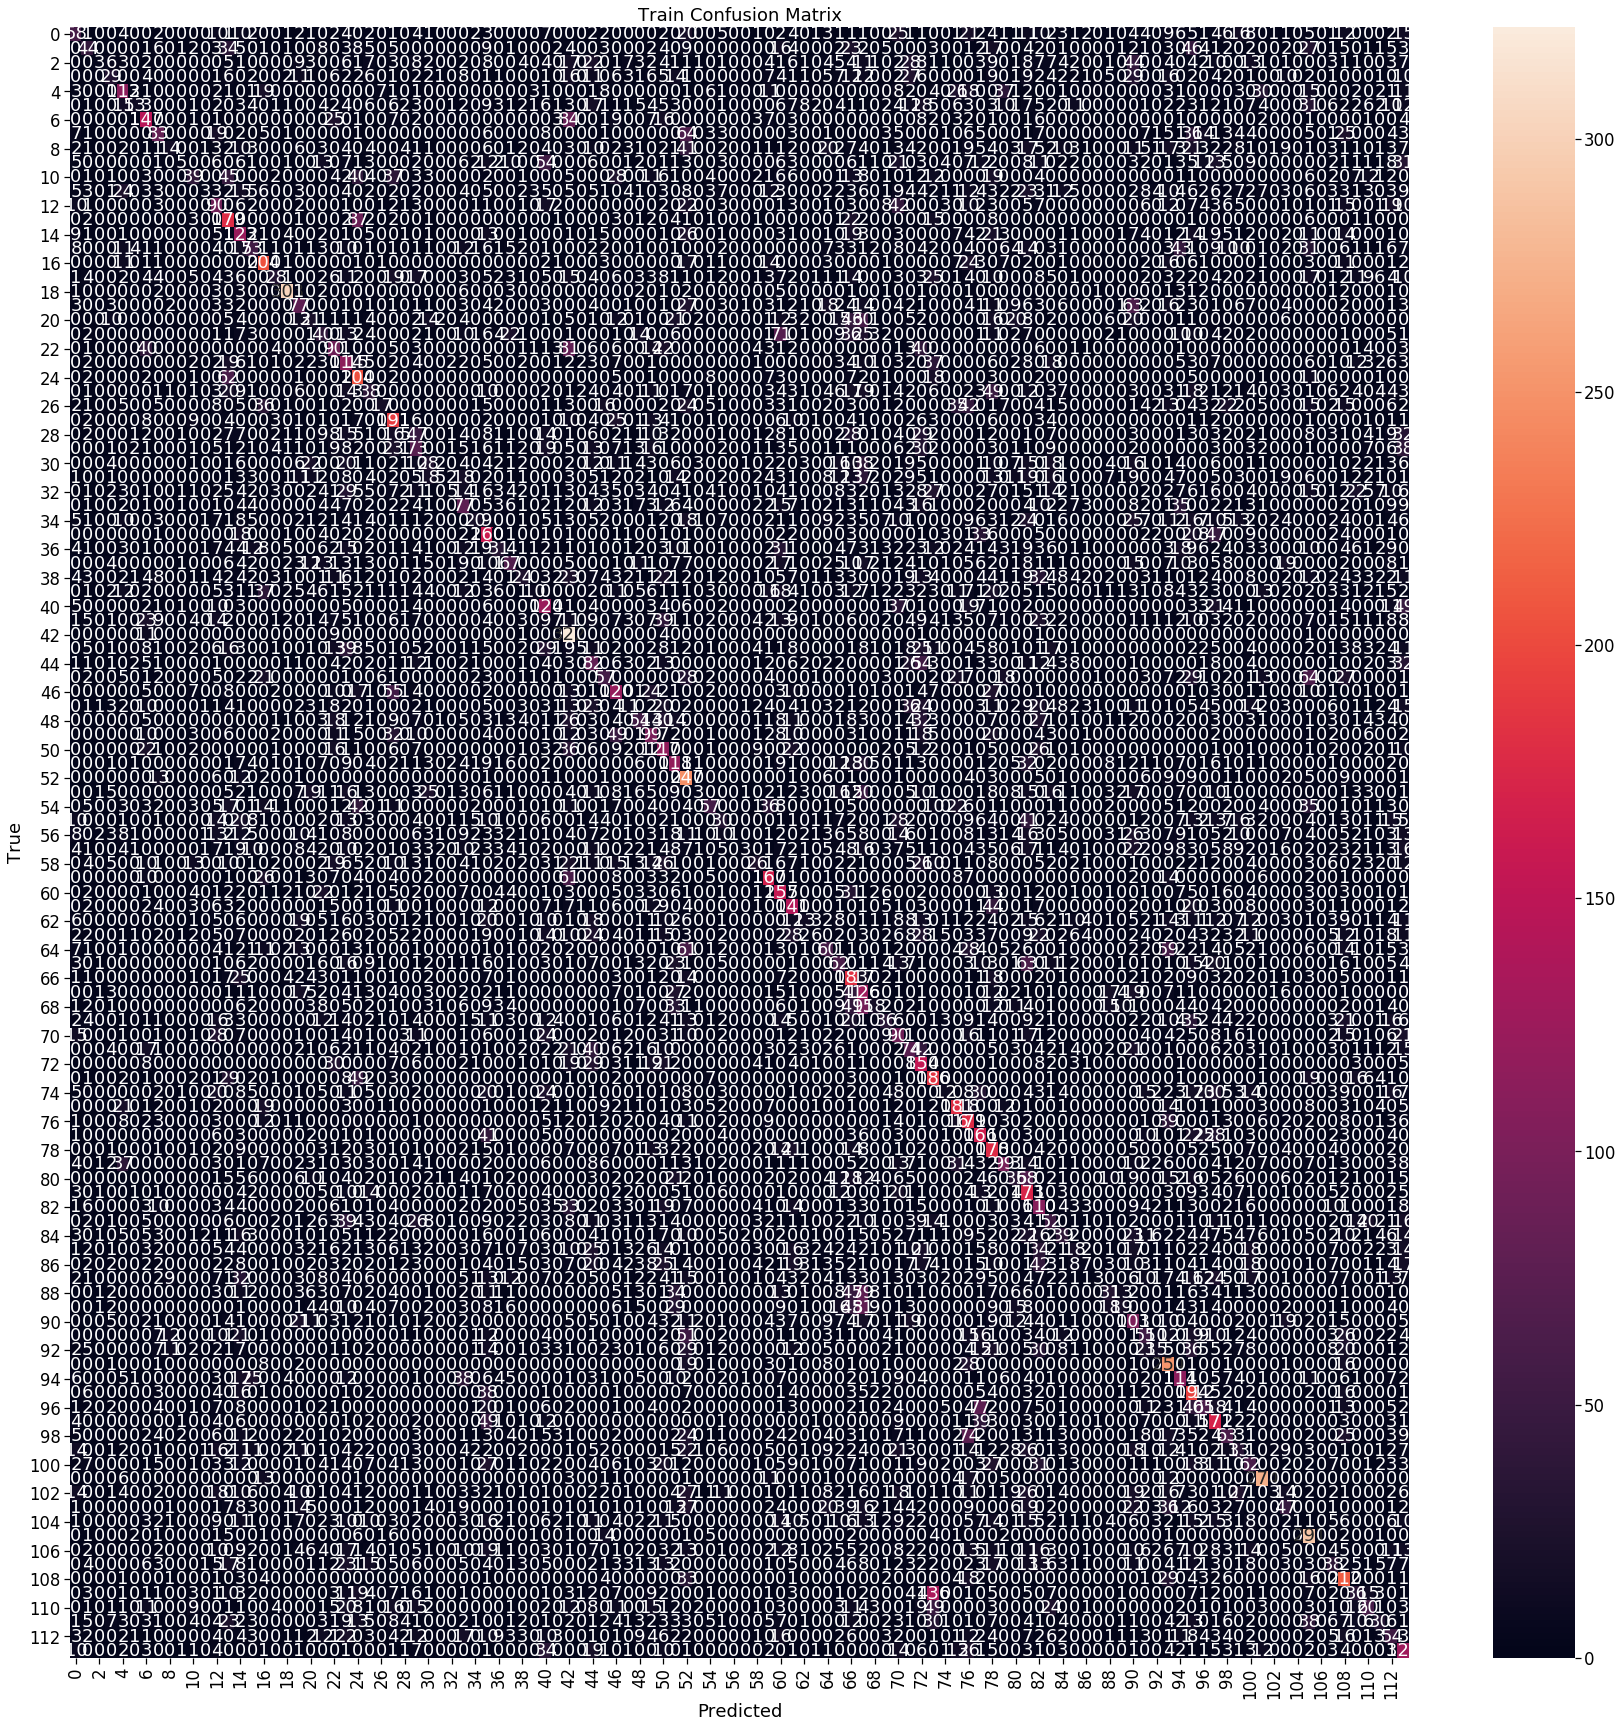

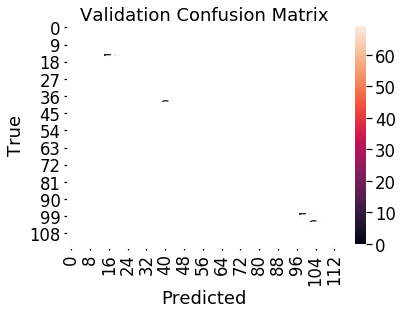

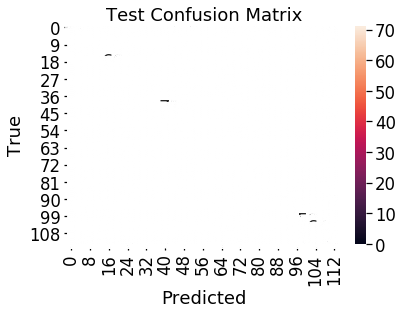

In [34]:
report_model_performance(pipe_elm, X_train, X_valid, X_test, y_train, y_valid, y_test)

In [ ]:
save_model(pipe_elm, "elm")